In [2]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import pandas as pd
import matplotlib.pyplot as plt
from regression_utils import *

In [132]:
# ETSWD Data processing
original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])

#Differenced the data by 1 and the set is stationary.
monthly_water_vols['diff1'] = monthly_water_vols['Water Volume'].diff(1)

#Log of water volume
monthly_water_vols["Log Water Volume"] = np.log1p(monthly_water_vols["Water Volume"])

In [133]:
# External data processing

#RRC Oil production
prod_df = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\ProductionDataQuery_monthlyTotals_ReportCsv(1).csv')
print(prod_df.head())
print(prod_df.columns)
print(prod_df['Date'].dtype)
prod_df['Date'] = prod_df['Date'].str.strip()

# format and sort oil production
prod_df = prod_df[['Date', 'Barrels']].copy()
prod_df['Date'] = pd.to_datetime(prod_df['Date'], format="%b %Y")
prod_df = prod_df.sort_values('Date')
print(prod_df['Date'].dtype)

#FRED Brent-Crude oil pride index
price_df = pd.read_csv(r'C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\MCOILBRENTEU.csv')
price_df = price_df[['Date', 'Price']].copy()
price_df['Date'] = pd.to_datetime(price_df['Date'])
price_df = price_df.sort_values('Date')

        Date  Barrels  Casinghead (MCF)
0   Jan 1998  1511920            514649
1   Feb 1998  1342069            455009
2   Mar 1998  1458160            524834
3   Apr 1998  1356408            490121
4   May 1998  1395849            544440
Index(['Date', 'Barrels', 'Casinghead (MCF)'], dtype='str')
str
datetime64[us]


In [134]:
# Data joining and continued preprocessing

#Combining the dataframes together for the SARIMA model
monthly_water_vols = monthly_water_vols.merge(prod_df[['Date','Barrels']], on = 'Date', how = 'left')
monthly_water_vols = monthly_water_vols.merge(price_df[['Date','Price']], on = 'Date', how = 'left')

#Creating lagged variables
monthly_water_vols["Lagged Water Volume"] = monthly_water_vols["Water Volume"].shift(1)
monthly_water_vols["Lagged Barrels"] = monthly_water_vols["Barrels"].shift(1)
monthly_water_vols["Lagged Price"] = monthly_water_vols["Price"].shift(1)

#Log of Lagged Water Volume
monthly_water_vols["Log Lagged Water Volume"] = np.log1p(monthly_water_vols["Lagged Water Volume"])

#making a subset the subset for 28 year forecast
mask = (monthly_water_vols['Date'] >= '1998-02-01') & (monthly_water_vols['Date'] <= '2026-05-01')
large_subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (large_subset['Date'] >= '1998-02-01') & (large_subset['Date'] < '2025-12-01')
large_training = large_subset[training_mask]

#Assigning Validation data
validation_mask = (large_subset['Date'] >= '2026-01-01') & (large_subset['Date'] <= '2026-05-01')
large_validation = large_subset[validation_mask]


#making a subset for the post-COVID forcast
mask = (monthly_water_vols['Date'] >= '2021-01-01') & (monthly_water_vols['Date'] <= '2026-05-01')
small_subset = monthly_water_vols[mask]

#Assigning Training data set
training_mask = (small_subset['Date'] >= '2021-01-01') & (small_subset['Date'] <= '2025-12-01')
small_training = small_subset[training_mask]

#Assigning Validation data
validation_mask = (small_subset['Date'] >= '2026-01-01') & (small_subset['Date'] <= '2026-05-01')
small_validation = small_subset[validation_mask]

small_training.head()

,Water Volume,Date,diff1,Log Water Volume,Barrels,Price,Lagged Water Volume,Lagged Barrels,Lagged Price,Log Lagged Water Volume
276,20649009.0,2021-01-01,-987825.0,16.843178,155107.0,54.77,21636834.0,168439.0,49.99,16.889908
277,17129464.0,2021-02-01,-3519545.0,16.656311,132098.0,62.28,20649009.0,155107.0,54.77,16.843178
278,20907538.0,2021-03-01,3778074.0,16.855620,164828.0,65.41,17129464.0,132098.0,62.28,16.656311
279,20505507.0,2021-04-01,-402031.0,16.836204,163017.0,64.81,20907538.0,164828.0,65.41,16.855620
280,21324192.0,2021-05-01,818685.0,16.875353,161649.0,68.53,20505507.0,163017.0,64.81,16.836204


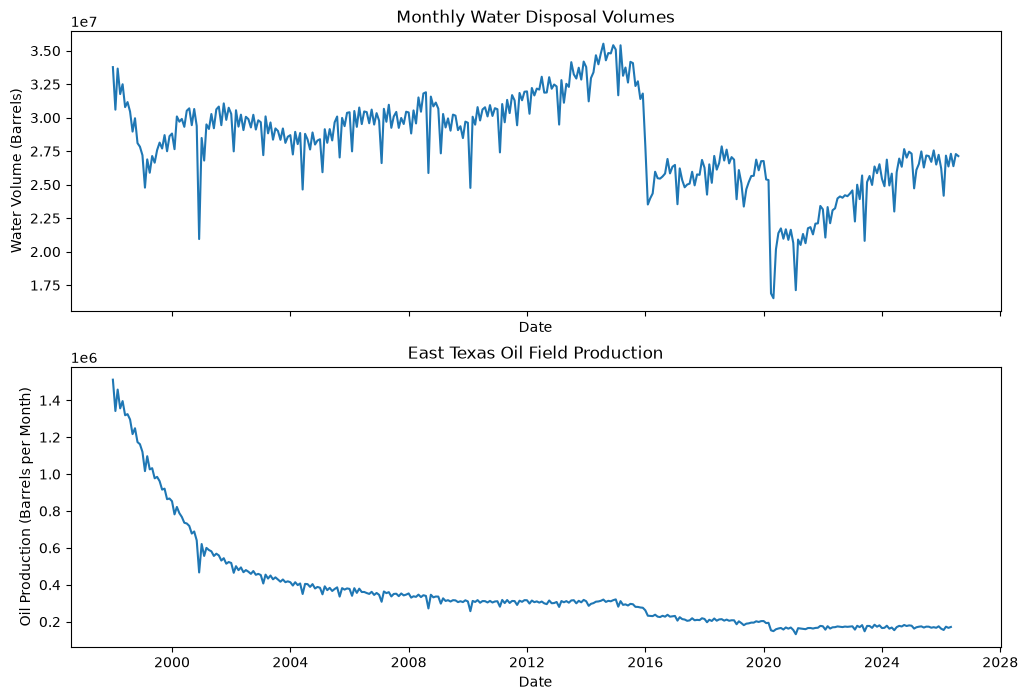

In [121]:
# Data is clean from the SARIMA script, I must figure out how to plot this data.
plt.ion()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12,8),sharex=True)

ax1.plot(monthly_water_vols['Date'], monthly_water_vols['Water Volume'], label = 'Water Disposal Volume')
ax1.set_title('Monthly Water Disposal Volumes')
ax1.set_xlabel('Date')
ax1.set_ylabel('Water Volume (Barrels)')
fig.savefig("Monthly Water Volumes")
           
#Figure for the oil_prod dataframe
ax2.plot(prod_df['Date'], prod_df['Barrels'])
ax2.set_xlabel('Date')
ax2.set_ylabel('Oil Production (Barrels per Month)')
ax2.set_title('East Texas Oil Field Production')

plt.show()

<Axes: >

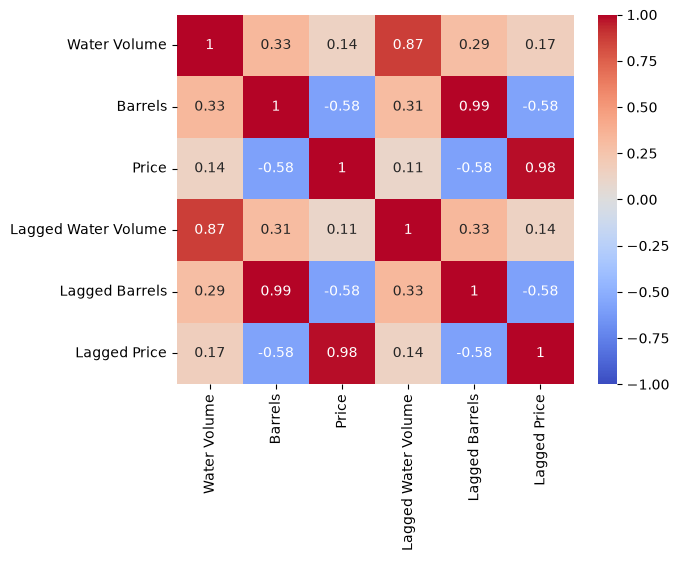

In [10]:
#correlation plot between disposal volumes and exogenous variables
corr_data = monthly_water_vols[["Water Volume", "Barrels", "Price", "Lagged Water Volume", "Lagged Barrels", "Lagged Price"]]
corr_matrix = corr_data.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

In [11]:
#check for series stationarity
def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag = 'AIC')
    p_value = result[1]
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Stationary' if p_value < 0.05 else 'Non-stationary\n')

check_stationarity(large_training['Water Volume'])

#This is the KPSS test. This checks for stationarity of the series by assuming it is stationary. A high KPSS statistics and low p-value indicate that the series is non-stationary
stat, p_value, lags, crit = kpss(large_training['Water Volume']) 

print("KPSS Statistic:", stat)
print("p-value:", p_value)
print("Critical Values:", crit)
print("Lags used:", lags)



ADF Statistic: -1.7940815750237806
p-value: 0.38340396105902924
Non-stationary

KPSS Statistic: 1.0497386759782068
p-value: 0.01
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Lags used: 11


C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\3266119532.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stat, p_value, lags, crit = kpss(large_training['Water Volume'])


ADF Statistic: -1.863115732369083
p-value: 0.3496065074679907
Non-stationary


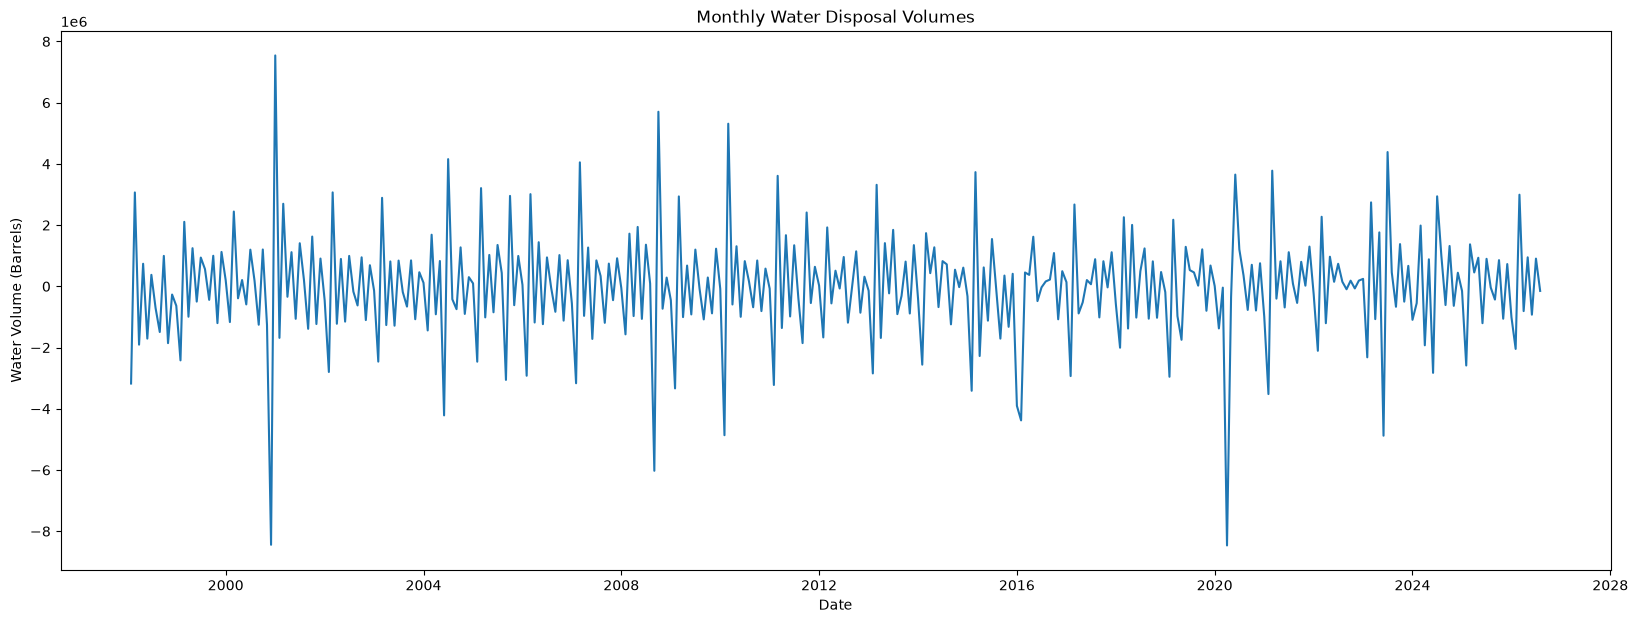

In [12]:
#checking the series for stationarity (AD Fuller test)
def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag = 'AIC')
    p_value = result[1]
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Stationary' if p_value < 0.05 else 'Non-stationary')

check_stationarity(monthly_water_vols["Water Volume"])
# Data is clean from the SARIMA script, I must figure out how to plot this data.

fig, ax = plt.subplots(figsize=(20,7))

ax.plot(monthly_water_vols['Date'], monthly_water_vols['diff1'], label = 'Water Disposal Volume')
ax.set_title('Monthly Water Disposal Volumes')
ax.set_xlabel('Date')
ax.set_ylabel('Water Volume (Barrels)')
fig.savefig("Monthly Water Volumes")
plt.show()            

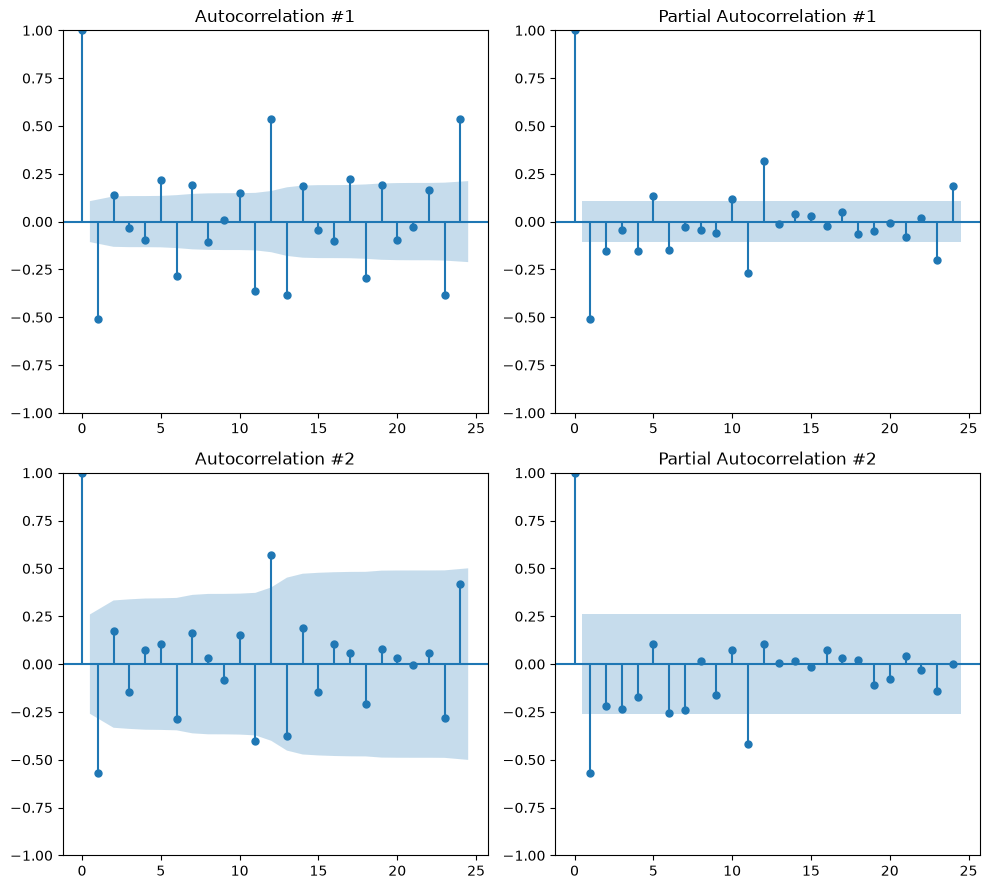

In [162]:

#AUTOCORRELATION FOR 1998 TO 2025
COVID_training_mask = (cleaned["Date"] >= "2021-01") & (cleaned["Date"] <= "2025-09" )
COVID_training = cleaned[COVID_training_mask]
#converting series to array
training_data_large = np.asarray(large_training['diff1'])
training_data_small = np.asarray(COVID_training["diff1"])

fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (10, 9))

plot_acf(training_data_large, ax=axes[0,0], lags = 24)
axes[0,0].set_title("Autocorrelation #1")

plot_pacf(training_data_large, ax=axes[0,1], lags = 24)
axes[0,1].set_title("Partial Autocorrelation #1")

plot_acf(training_data_small, ax=axes[1,0], lags = 24)
axes[1,0].set_title("Autocorrelation #2")

plot_pacf(training_data_small, ax=axes[1,1], lags = 24)
axes[1,1].set_title("Partial Autocorrelation #2")

plt.tight_layout()
plt.show()


In [90]:
# using the auto arima function to test which parameters for the model are a good fit.
# optimal ARIMA(1,1,0)x(1,0,1,12)

#auto arima is called to find the correct parameters for the dataset
auto_arima(large_training['Water Volume'], m = 12, trace = True).summary()

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=10437.160, Time=0.92 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=10534.755, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=10482.382, Time=0.12 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=10489.089, Time=0.15 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=10532.772, Time=0.01 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=10494.973, Time=0.44 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=10486.325, Time=0.54 sec
 ARIMA(2,1,2)(2,0,1)[12] intercept   : AIC=10437.091, Time=2.24 sec
 ARIMA(2,1,2)(2,0,0)[12] intercept   : AIC=10463.036, Time=1.89 sec
 ARIMA(2,1,2)(2,0,2)[12] intercept   : AIC=10439.090, Time=3.36 sec
 ARIMA(2,1,2)(1,0,2)[12] intercept   : AIC=10437.100, Time=1.78 sec
 ARIMA(1,1,2)(2,0,1)[12] intercept   : AIC=10435.244, Time=1.49 sec
 ARIMA(1,1,2)(1,0,1)[12] intercept   : AIC=10435.334, Time=0.44 sec
 ARIMA(1,1,2)(2,0,0)[12] intercept   : AIC=10461.432, Time=1.47 sec
 ARIM

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                                    y   No. Observations:                  334
Model:             SARIMAX(1, 1, 2)x(1, 0, [1], 12)   Log Likelihood               -5209.016
Date:                              Tue, 06 Oct 2026   AIC                          10430.032
Time:                                      08:05:06   BIC                          10452.881
Sample:                                           0   HQIC                         10439.143
                                              - 334                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8705      0.078     11.220      0.000       0.718       1.023
ma.L1         -1.0305      0.071    -14.449      0.000      -1.170      -0.891
ma.L2          0.0918      0.029      3.158      0.002       0.035       0.149
ar.S.L12       0.9114      0.027     34.003      0.000       0.859       0.964
ma.S.L12      -0.8094      0.037    -21.653      0.000      -0.883      -0.736
sigma2      2.257e+12    2.3e-14   9.81e+25      0.000    2.26e+12    2.26e+12
===================================================================================
Ljung-Box (L1) (Q):                  24.59   Jarque-Bera (JB):              1131.42
Prob(Q):                              0.00   Prob(JB):                         0.00
Heteroskedasticity (H):               0.47   Skew:                            -1.08
Prob(H) (two-sided):                  0.00   Kurtosis:                        11.77
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.4e+41. Standard errors may be unstable.
"""

In [20]:
#Creating the single column x_df for the adjusted r_squared measurement.
print(monthly_water_vols.shape[1])
testing_df = monthly_water_vols[["Barrels"]]
print(testing_df.shape[1])

10
1


R-squared: 0.81274379892852
Adjusted R-squared: 0.7503250652380267
                                     SARIMAX Results                                      
Dep. Variable:                       Water Volume   No. Observations:                  334
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood               -5015.058
Date:                            Tue, 06 Oct 2026   AIC                          10036.115
Time:                                    09:37:02   BIC                          10047.430
Sample:                                         0   HQIC                         10040.633
                                            - 334                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1944      0.025     -7.817    

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\3637799501.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


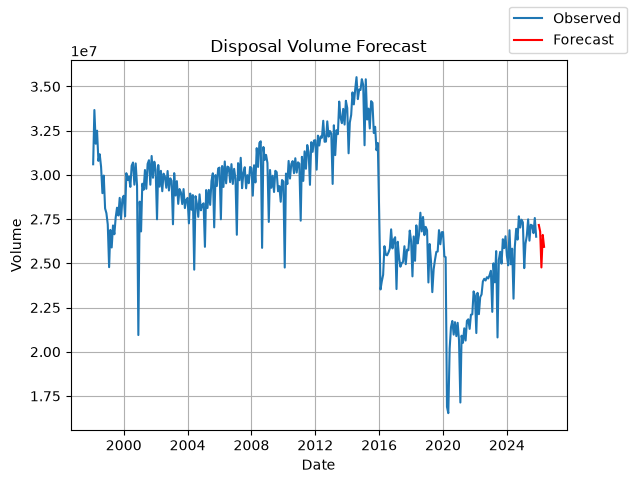

In [193]:
#Using the SARIMAX model with endogenous variable Water Volume
model = SARIMAX(
    large_training['Water Volume'],  
    order = (0,1,1), 
    seasonal_order = (0,1,1,12)
    
)
results = model.fit()
forecast_periods = len(large_validation)
forecast = results.forecast(forecast_periods)
r_squared = R_squared(large_validation['Water Volume'], forecast)
adjusted = adj_R_squared(large_validation["Water Volume"], forecast, testing_df)


print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(large_training['Date'], large_training['Water Volume'], label='Observed')
ax.plot(large_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


R-squared: 0.7261272343257903
Adjusted R-squared: 0.634836312434387
                                      SARIMAX Results                                       
Dep. Variable:                     Log Water Volume   No. Observations:                  334
Model:             SARIMAX(1, 1, 0)x(0, 1, [1], 12)   Log Likelihood                 499.607
Date:                              Tue, 06 Oct 2026   AIC                           -993.213
Time:                                      09:32:58   BIC                           -981.899
Sample:                                           0   HQIC                          -988.695
                                              - 334                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2211      0.0

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\1999165734.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


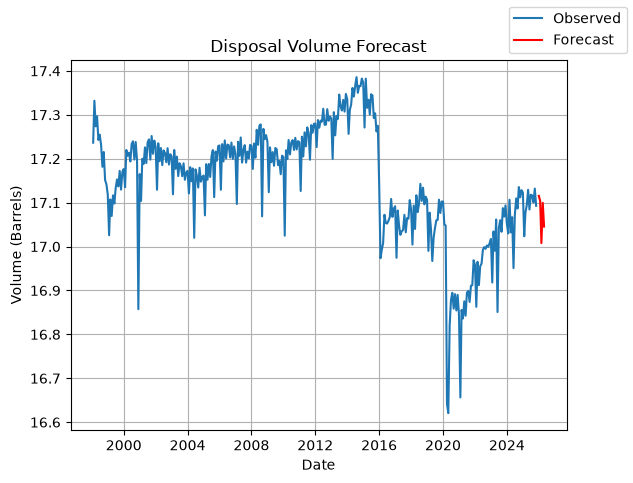

In [191]:
#SARIMAX model with endogenous variable Log Water Volume
model = SARIMAX(
    large_training[['Log Water Volume']],
    order = (1,1,0), 
    seasonal_order = (0,1,1,12)
    
)
results = model.fit()
forecast_periods = len(large_validation)
forecast = results.forecast(forecast_periods)
r_squared = R_squared(large_validation['Log Water Volume'], forecast)
adjusted = adj_R_squared(large_validation['Log Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(large_training['Date'], large_training['Log Water Volume'], label='Observed')
ax.plot(large_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume (Barrels)")
ax.grid()
fig.legend()
fig.show()


R-squared: 0.537674722702363
Adjusted R-squared: 0.38356629693648403
                                     SARIMAX Results                                      
Dep. Variable:                       Water Volume   No. Observations:                  334
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood               -4861.022
Date:                            Tue, 06 Oct 2026   AIC                           9730.045
Time:                                    09:17:45   BIC                           9745.130
Sample:                                         0   HQIC                          9736.068
                                            - 334                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Barrels       57.9509      1.294     44.779  

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\3670665663.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


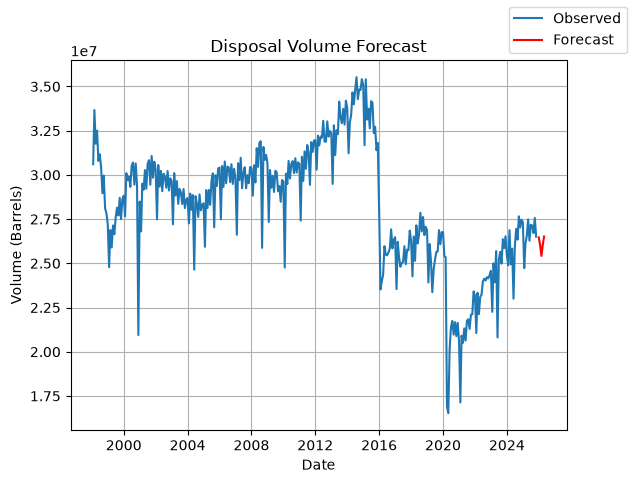

In [175]:
#Using the SARIMAX model with the exogenous variable Barrels 
model = SARIMAX(
    large_training[['Water Volume']],
    exog = large_training[["Barrels"]],
    order = (0,1,1), 
    seasonal_order = (0,1,1,12)
    
)
results = model.fit()
forecast_periods = len(large_validation)
forecast = results.forecast(forecast_periods, exog = large_validation["Barrels"])
r_squared = R_squared(large_validation['Water Volume'], forecast)
adjusted = adj_R_squared(large_validation['Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(large_training['Date'], large_training['Water Volume'], label='Observed')
ax.plot(large_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume (Barrels)")
ax.grid()
fig.legend()
fig.show()


C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\2284132958.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


R-squared: 0.6952610322511638
Adjusted R-squared: 0.5936813763348849
                                     SARIMAX Results                                      
Dep. Variable:                   Log Water Volume   No. Observations:                  334
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 600.217
Date:                            Tue, 06 Oct 2026   AIC                          -1192.434
Time:                                    09:18:01   BIC                          -1177.348
Sample:                                         0   HQIC                         -1186.410
                                            - 334                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Barrels     1.739e-06   1.09e-07     15.959  

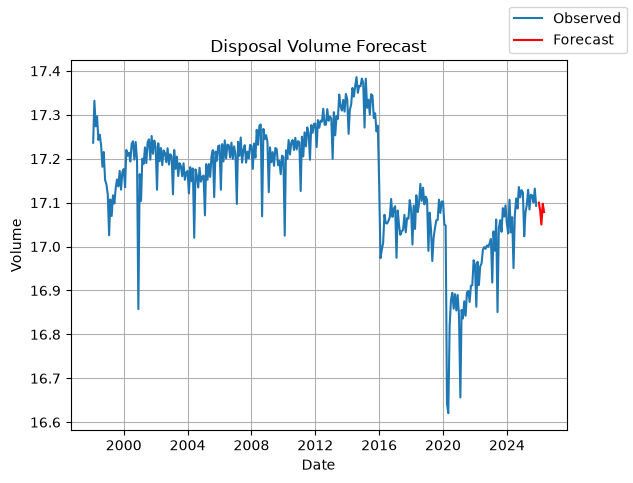

In [176]:
#SARIMAX model with Log Water Volume and exogenous variable Barrels.
model = SARIMAX(
    large_training['Log Water Volume'], 
    exog = large_training['Barrels'], 
    order = (0,1,1), 
    seasonal_order = (0,1,1,12)
    
)

results = model.fit()
forecast_periods = len(large_validation)
forecast = results.forecast(forecast_periods, exog = large_validation['Barrels'])
r_squared = R_squared(large_validation['Log Water Volume'], forecast)
adjusted = adj_R_squared(large_validation['Log Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(large_training['Date'], large_training['Log Water Volume'], label='Observed')
ax.plot(large_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


R-squared: 0.5954408638307727
Adjusted R-squared: 0.46058781844103025
                                     SARIMAX Results                                      
Dep. Variable:                       Water Volume   No. Observations:                  334
Model:             SARIMAX(0, 1, 1)x(1, 0, 1, 12)   Log Likelihood               -5054.823
Date:                            Tue, 06 Oct 2026   AIC                          10121.645
Time:                                    09:13:47   BIC                          10144.494
Sample:                                         0   HQIC                         10130.757
                                            - 334                                         
Covariance Type:                              opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Barrels           32.7005      1.285

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\1428994434.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


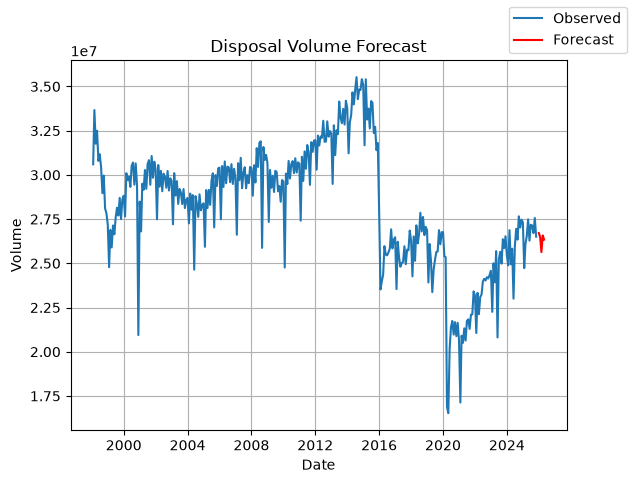

In [169]:
#SARIMAX model with Water Volume and exogenous variable Barrels and Lagged Barrels
model = SARIMAX(
    large_training['Water Volume'], 
    exog = large_training[['Barrels', 'Lagged Barrels']], 
    order = (0,1,1), 
    seasonal_order = (1,0,1,12)
    
)

results = model.fit()
forecast_periods = len(large_validation)
forecast = results.forecast(forecast_periods, exog = large_validation[['Barrels', 'Lagged Barrels']])
r_squared = R_squared(large_validation['Water Volume'], forecast)
adjusted = adj_R_squared(large_validation['Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(large_training['Date'], large_training['Water Volume'], label='Observed')
ax.plot(large_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()

R-squared: 0.8490466209838292
Adjusted R-squared: 0.7987288279784389
                                      SARIMAX Results                                       
Dep. Variable:                         Water Volume   No. Observations:                  334
Model:             SARIMAX(1, 1, 0)x(1, 0, [1], 12)   Log Likelihood               -5173.629
Date:                              Tue, 06 Oct 2026   AIC                          10357.258
Time:                                      08:00:11   BIC                          10376.299
Sample:                                           0   HQIC                         10364.851
                                              - 334                                         
Covariance Type:                                opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Lagged Barrels    22.

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\2053247981.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


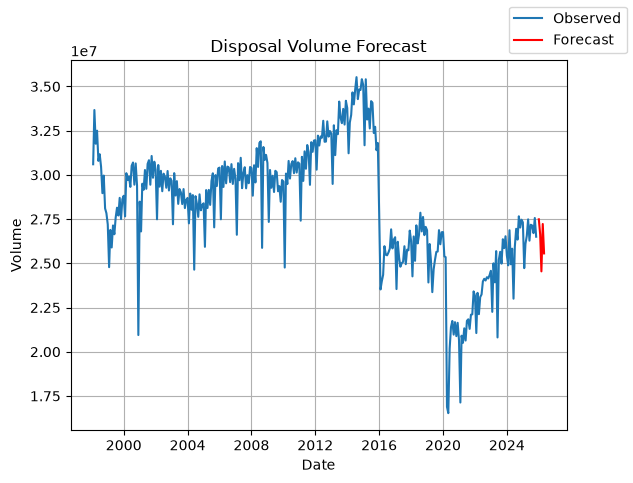

In [87]:
#SARIMAX model with Water Volume and exogenous variable Lagged Barrels.
model = SARIMAX(
    large_training['Water Volume'], 
    exog = large_training['Lagged Barrels'], 
    order = (1,1,0), 
    seasonal_order = (1,0,1,12)
    
)

results = model.fit()
forecast_periods = len(large_validation)
forecast = results.forecast(forecast_periods, exog = large_validation['Lagged Barrels'])
r_squared = R_squared(large_validation['Water Volume'], forecast)
adjusted = adj_R_squared(large_validation['Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(large_training['Date'], large_training['Water Volume'], label='Observed')
ax.plot(large_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()

C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\2594856743.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


R-squared: 0.1867900195349783
Adjusted R-squared: -0.08427997395336218
                                      SARIMAX Results                                       
Dep. Variable:                     Log Water Volume   No. Observations:                  334
Model:             SARIMAX(1, 1, 0)x(1, 0, [1], 12)   Log Likelihood                 623.243
Date:                              Tue, 06 Oct 2026   AIC                          -1234.485
Time:                                      08:47:32   BIC                          -1211.636
Sample:                                           0   HQIC                         -1225.374
                                              - 334                                         
Covariance Type:                                opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Barrels         1.9

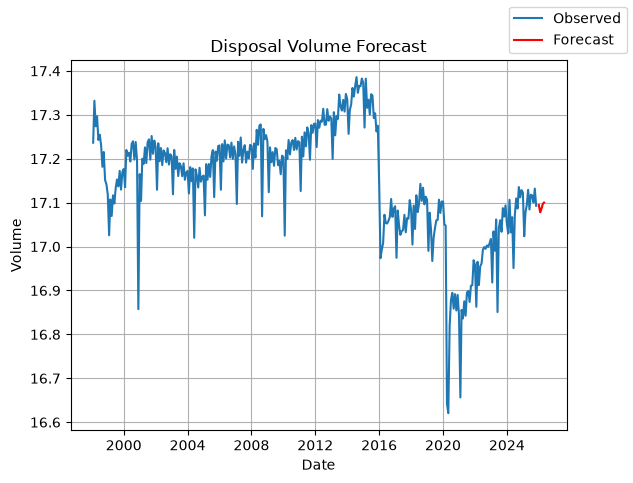

In [143]:
#SARIMAX model with Log Water Volume and exogenous variable Barrels and Lagged Barrels
model = SARIMAX(
    large_training['Log Water Volume'], 
    exog = large_training[['Barrels', 'Lagged Barrels']], 
    order = (1,1,0), 
    seasonal_order = (1,0,1,12)
    
)

results = model.fit()
forecast_periods = len(large_validation)
forecast = results.forecast(forecast_periods, exog = large_validation[['Barrels', 'Lagged Barrels']])
r_squared = R_squared(large_validation['Log Water Volume'], forecast)
adjusted = adj_R_squared(large_validation['Log Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(large_training['Date'], large_training['Log Water Volume'], label='Observed')
ax.plot(large_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()

C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\595734148.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


R-squared: -0.8039652402458106
Adjusted R-squared: -0.967962080268157
                                      SARIMAX Results                                       
Dep. Variable:                     Log Water Volume   No. Observations:                  326
Model:             SARIMAX(1, 1, 0)x(1, 0, [1], 12)   Log Likelihood                 480.862
Date:                              Tue, 06 Oct 2026   AIC                           -951.723
Time:                                      08:27:36   BIC                           -932.804
Sample:                                           0   HQIC                          -944.173
                                              - 326                                         
Covariance Type:                                opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Lagged Barrels -1.00

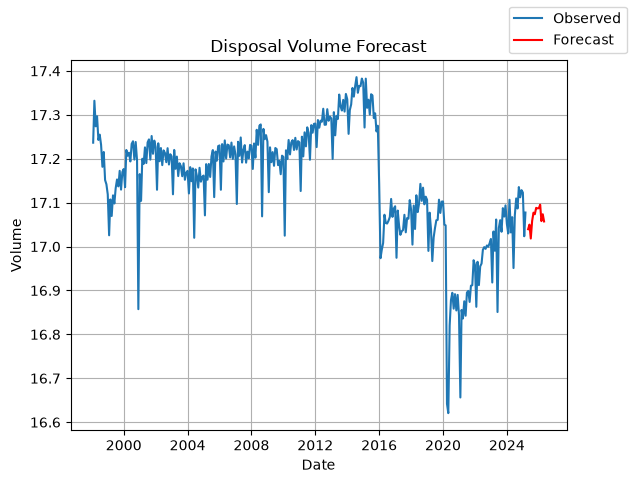

In [129]:
#SARIMAX model with Log Water Volume and exogenous variable Lagged Barrels.
model = SARIMAX(
    large_training['Log Water Volume'], 
    exog = large_training['Lagged Barrels'], 
    order = (1,1,0), 
    seasonal_order = (1,0,1,12)
    
)

results = model.fit()
forecast_periods = len(large_validation)
forecast = results.forecast(forecast_periods, exog = large_validation['Lagged Barrels'])
r_squared = R_squared(large_validation['Log Water Volume'], forecast)
adjusted = adj_R_squared(large_validation['Log Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(large_training['Date'], large_training['Log Water Volume'], label='Observed')
ax.plot(large_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()

R-squared: -0.5410036158733607
Adjusted R-squared: -1.0546714878311474
                               SARIMAX Results                                
Dep. Variable:           Water Volume   No. Observations:                   60
Model:               SARIMAX(1, 1, 0)   Log Likelihood                -916.931
Date:                Tue, 06 Oct 2026   AIC                           1837.862
Time:                        08:30:38   BIC                           1842.017
Sample:                             0   HQIC                          1839.483
                                 - 60                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2820      0.028    -10.037      0.000      -0.337      -0.227
sigma2      1.494e+12   5.06e-16   2.96e+27      0.000    1.

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\1851859534.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


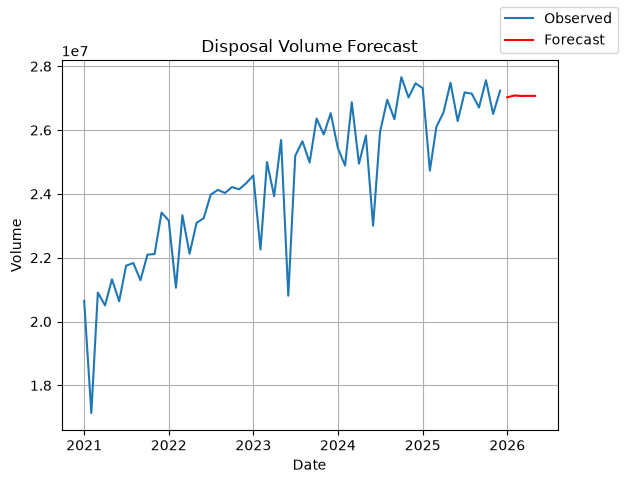

In [137]:
# Post-Covid SARIMAX model 
model = SARIMAX(
    small_training['Water Volume'],
    order = (1,1,0), 
    seasonal_order = (0,0,0,12)
    
)

results = model.fit()
forecast_periods = len(small_validation)
forecast = results.forecast(forecast_periods)
r_squared = R_squared(small_validation['Water Volume'], forecast)
adjusted = adj_R_squared(small_validation['Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(small_training['Date'], small_training['Water Volume'], label='Observed')
ax.plot(small_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()

R-squared: -0.47467788619513573
Adjusted R-squared: -0.9662371815935142
                               SARIMAX Results                                
Dep. Variable:       Log Water Volume   No. Observations:                   60
Model:               SARIMAX(1, 1, 0)   Log Likelihood                  86.872
Date:                Tue, 06 Oct 2026   AIC                           -169.743
Time:                        08:31:30   BIC                           -165.588
Sample:                             0   HQIC                          -168.121
                                 - 60                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6549      0.062    -10.519      0.000      -0.777      -0.533
sigma2         0.0031      0.000      6.974      0.000     

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\4129761292.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


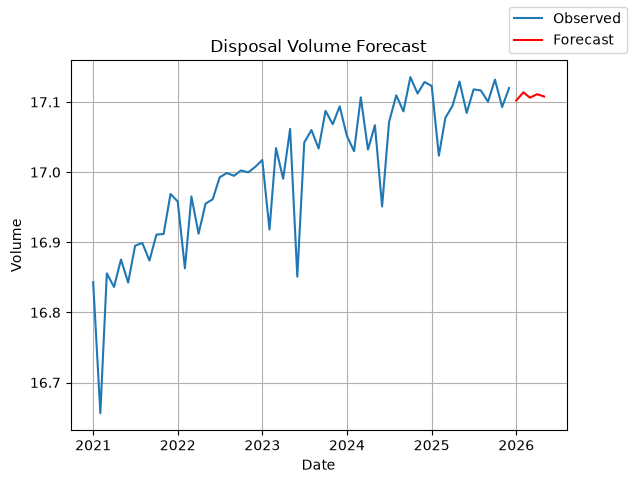

In [138]:
# Post-Covid SARIMAX model 
model = SARIMAX(
    small_training['Log Water Volume'],
    order = (1,1,0), 
    seasonal_order = (0,0,0,12)
    
)

results = model.fit()
forecast_periods = len(small_validation)
forecast = results.forecast(forecast_periods)
r_squared = R_squared(small_validation['Log Water Volume'], forecast)
adjusted = adj_R_squared(small_validation['Log Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(small_training['Date'], small_training['Log Water Volume'], label='Observed')
ax.plot(small_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()

R-squared: 0.8663590214810035
Adjusted R-squared: 0.8218120286413381
                               SARIMAX Results                                
Dep. Variable:           Water Volume   No. Observations:                   60
Model:               SARIMAX(1, 1, 0)   Log Likelihood                -842.708
Date:                Tue, 06 Oct 2026   AIC                           1691.416
Time:                        08:25:21   BIC                           1697.649
Sample:                             0   HQIC                          1693.849
                                 - 60                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Barrels      128.9100      4.347     29.657      0.000     120.390     137.429
ar.L1         -0.4341      0.113     -3.835      0.000      -0

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\4293171066.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


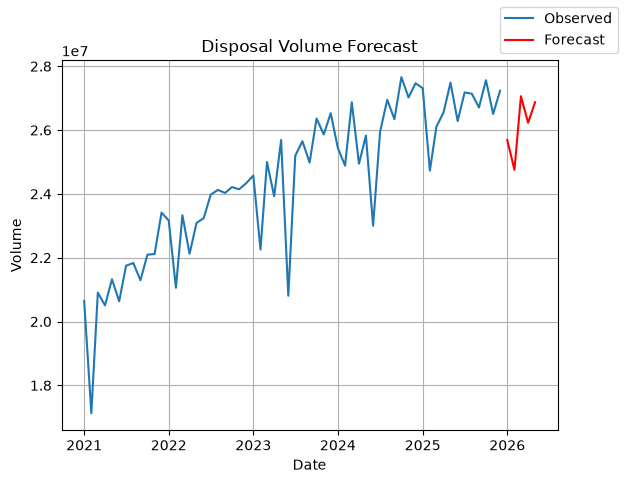

In [123]:
# Post-Covid SARIMAX model with exogenous variable Barrels
model = SARIMAX(
    small_training['Water Volume'],
    exog = small_training['Barrels'],
    order = (1,1,0), 
    seasonal_order = (0,0,0,12)
    
)

results = model.fit()
forecast_periods = len(small_validation)
forecast = results.forecast(forecast_periods, exog = small_validation['Barrels'])
r_squared = R_squared(small_validation['Water Volume'], forecast)
adjusted = adj_R_squared(small_validation['Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(small_training['Date'], small_training['Water Volume'], label='Observed')
ax.plot(small_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


R-squared: 0.8804075063527048
Adjusted R-squared: 0.8405433418036065
                               SARIMAX Results                                
Dep. Variable:       Log Water Volume   No. Observations:                   60
Model:               SARIMAX(0, 1, 1)   Log Likelihood                 155.214
Date:                Tue, 06 Oct 2026   AIC                           -304.427
Time:                        09:49:29   BIC                           -298.195
Sample:                             0   HQIC                          -301.994
                                 - 60                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Barrels     5.903e-06   1.78e-07     33.093      0.000    5.55e-06    6.25e-06
ma.L1         -0.4632      0.090     -5.141      0.000      -0

C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\2726201449.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


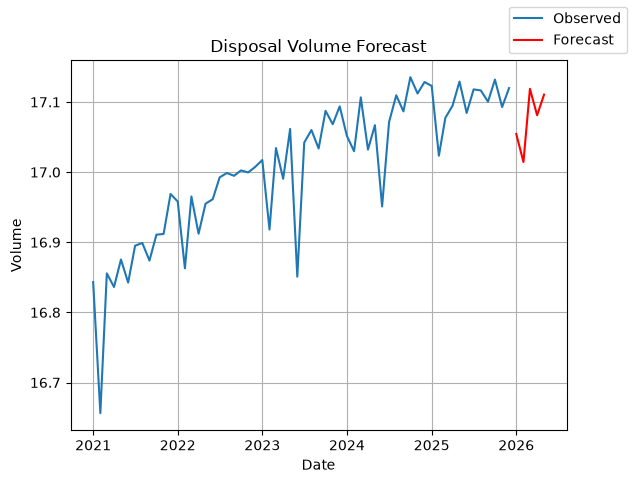

In [194]:
# Post-Covid SARIMAX model with exogenous variables
model = SARIMAX(
    small_training['Log Water Volume'],
    exog = small_training['Barrels'],
    order = (0,1,1), 
    seasonal_order = (0,0,0,12)
    
)

results = model.fit()
forecast_periods = len(small_validation)
forecast = results.forecast(forecast_periods, exog = small_validation['Barrels'])
r_squared = R_squared(small_validation['Log Water Volume'], forecast)
adjusted = adj_R_squared(small_validation['Log Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(small_training['Date'], small_training['Log Water Volume'], label='Observed')
ax.plot(small_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


R-squared: 0.8746611733483338
Adjusted R-squared: 0.8328815644644451
                               SARIMAX Results                                
Dep. Variable:           Water Volume   No. Observations:                   60
Model:               SARIMAX(1, 1, 0)   Log Likelihood                -842.157
Date:                Tue, 06 Oct 2026   AIC                           1692.313
Time:                        08:33:18   BIC                           1700.623
Sample:                             0   HQIC                          1695.557
                                 - 60                                         
Covariance Type:                  opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Barrels          127.7213      3.690     34.609      0.000     120.488     134.954
Lagged Barrels     4.4213      3.290      1.344   

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\2853828226.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


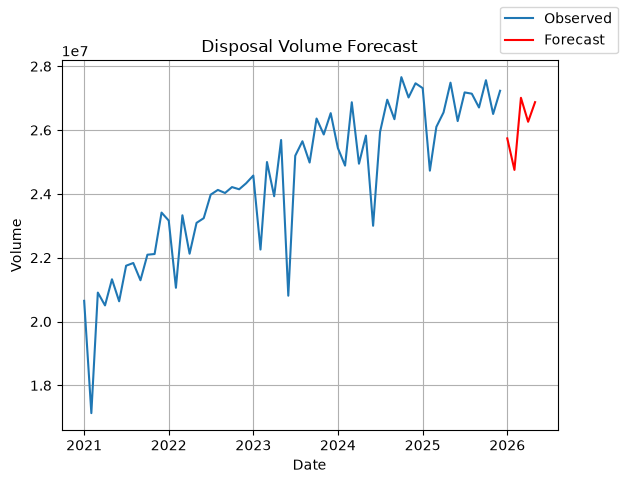

In [139]:
# Post-Covid SARIMAX model with exogenous variables
model = SARIMAX(
    small_training['Water Volume'],
    exog = small_training[['Barrels', 'Lagged Barrels']],
    order = (1,1,0), 
    seasonal_order = (0,0,0,12)
    
)

results = model.fit()
forecast_periods = len(small_validation)
forecast = results.forecast(forecast_periods, exog = small_validation[['Barrels', 'Lagged Barrels']])
r_squared = R_squared(small_validation['Water Volume'], forecast)
adjusted = adj_R_squared(small_validation['Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(small_training['Date'], small_training['Water Volume'], label='Observed')
ax.plot(small_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


R-squared: 0.868323350419679
Adjusted R-squared: 0.8244311338929053
                               SARIMAX Results                                
Dep. Variable:       Log Water Volume   No. Observations:                   60
Model:               SARIMAX(1, 1, 0)   Log Likelihood                 160.805
Date:                Tue, 06 Oct 2026   AIC                           -313.609
Time:                        08:33:52   BIC                           -305.299
Sample:                             0   HQIC                          -310.365
                                 - 60                                         
Covariance Type:                  opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Barrels         6.128e-06   1.87e-07     32.740      0.000    5.76e-06    6.49e-06
Lagged Barrels  4.011e-07   1.99e-07      2.019    

C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\3032005039.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


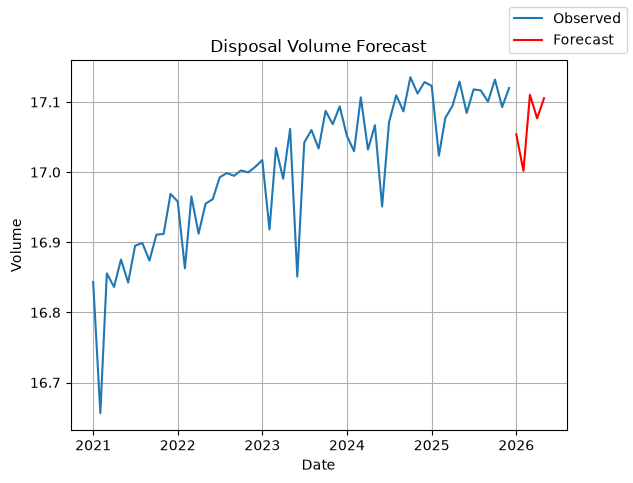

In [140]:
# Post-Covid SARIMAX model with exogenous variables
model = SARIMAX(
    small_training['Log Water Volume'],
    exog = small_training[['Barrels', 'Lagged Barrels']],
    order = (1,1,0), 
    seasonal_order = (0,0,0,12)
    
)

results = model.fit()
forecast_periods = len(small_validation)
forecast = results.forecast(forecast_periods, exog = small_validation[['Barrels', 'Lagged Barrels']])
r_squared = R_squared(small_validation['Log Water Volume'], forecast)
adjusted = adj_R_squared(small_validation['Log Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(small_training['Date'], small_training['Log Water Volume'], label='Observed')
ax.plot(small_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


R-squared: -0.9234098591177045
Adjusted R-squared: -1.564546478823606
                               SARIMAX Results                                
Dep. Variable:           Water Volume   No. Observations:                   60
Model:               SARIMAX(1, 1, 0)   Log Likelihood                -911.029
Date:                Tue, 06 Oct 2026   AIC                           1828.058
Time:                        08:34:46   BIC                           1834.291
Sample:                             0   HQIC                          1830.491
                                 - 60                                         
Covariance Type:                  opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Lagged Barrels   -69.1462     17.780     -3.889      0.000    -103.994     -34.299
ar.L1             -0.1480      0.124     -1.196  

C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\3111271797.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


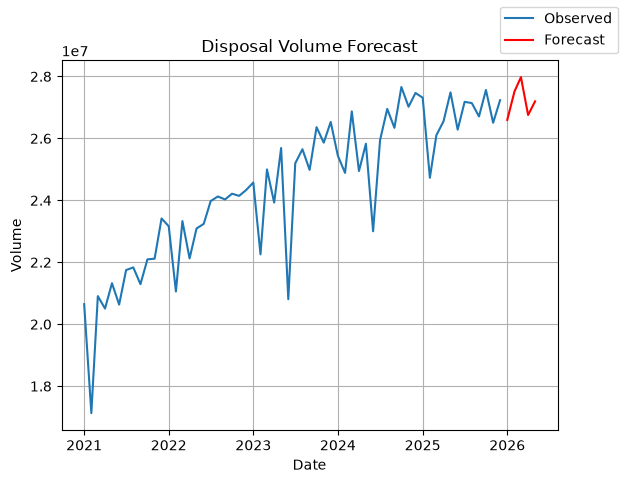

In [141]:
# Post-Covid SARIMAX model with exogenous variables
model = SARIMAX(
    small_training['Water Volume'],
    exog = small_training['Lagged Barrels'],
    order = (1,1,0), 
    seasonal_order = (0,0,0,12)
    
)

results = model.fit()
forecast_periods = len(small_validation)
forecast = results.forecast(forecast_periods, exog = small_validation['Lagged Barrels'])
r_squared = R_squared(small_validation['Water Volume'], forecast)
adjusted = adj_R_squared(small_validation['Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(small_training['Date'], small_training['Water Volume'], label='Observed')
ax.plot(small_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()


C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\LoganFrideley\AppData\Local\Temp\ipykernel_32024\3805437445.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


R-squared: -0.9315367107608632
Adjusted R-squared: -1.5753822810144844
                               SARIMAX Results                                
Dep. Variable:       Log Water Volume   No. Observations:                   60
Model:               SARIMAX(1, 1, 0)   Log Likelihood                  81.883
Date:                Tue, 06 Oct 2026   AIC                           -157.766
Time:                        08:35:50   BIC                           -151.534
Sample:                             0   HQIC                          -155.333
                                 - 60                                         
Covariance Type:                  opg                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Lagged Barrels -2.982e-06   8.78e-07     -3.397      0.001    -4.7e-06   -1.26e-06
ar.L1             -0.2493      0.148     -1.682 

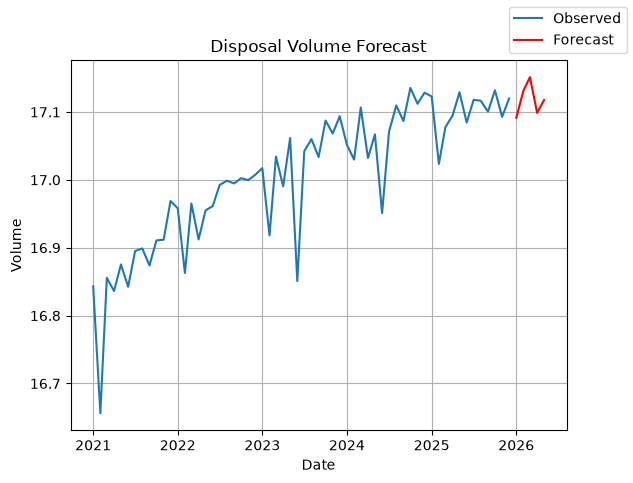

In [142]:
# Post-Covid SARIMAX model with exogenous variables
model = SARIMAX(
    small_training['Log Water Volume'],
    exog = small_training['Lagged Barrels'],
    order = (1,1,0), 
    seasonal_order = (0,0,0,12)
    
)

results = model.fit()
forecast_periods = len(small_validation)
forecast = results.forecast(forecast_periods, exog = small_validation['Lagged Barrels'])
r_squared = R_squared(small_validation['Log Water Volume'], forecast)
adjusted = adj_R_squared(small_validation['Log Water Volume'], forecast, testing_df)

print(f'R-squared: {r_squared}')
print(f'Adjusted R-squared: {adjusted}')
print(results.summary())

fig, ax = plt.subplots()
ax.plot(small_training['Date'], small_training['Log Water Volume'], label='Observed')
ax.plot(small_validation['Date'], forecast, label='Forecast', color='red')
ax.set_title("Disposal Volume Forecast")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")
ax.grid()
fig.legend()
fig.show()
